### Week 1 - Setup & Dataset (VigilantFace)

### environment setup run in terminal
1) python -m venv vigilantface
2) .\vigilantface\Scripts\Activate.ps1
3) pip install torch torchvision facenet-pytorch pandas numpy matplotlib opencv-python pillow scikit-learn jupyter
```
if using Colab just: !pip install facenet-pytorch (rest is preinstalled). GPU: Runtime -> Change runtime type -> GPU.

In [2]:
import torch
print(torch.__version__)
print(torch.version.cuda)

2.11.0+cu128
12.8


### -----------------------------------------------------------------------------------------------------------

### Libraries

In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image #this library used for image processing (open, rotate, crop, resize, save)
import torch 

'''
this line used to check if the device have CUDA (NVIDIA GPU)
that pytorch can use, if not it will use the cpu
'''
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("gpu available:", torch.cuda.is_available())

device: cuda
gpu available: True


### download CelebA
download manually from kaggle 

In [4]:
# hardcoded paths after download
base_path = "D:\\D_Downloads\\celebA"
img_dir = os.path.join(base_path, "img_align_celeba/img_align_celeba")
identity_file = os.path.join(base_path, "identity_CelebA.txt")
attr_file = os.path.join(base_path, "list_attr_celeba.csv")
landmark_file = os.path.join(base_path, "list_landmarks_align_celeba.csv")

# everything we generate goes here, so the raw dataset folder stays untouched
project_dir = "./celeba"
os.makedirs(project_dir, exist_ok=True)

# check every path exists before going further (cheaper than failing 3 cells later)
for p in [img_dir, identity_file, attr_file, landmark_file]:
    print("ok " if os.path.exists(p) else "MISSING", "->", p)

# os.listdir: This lists all files inside the image folder.
print("images found:", len(os.listdir(img_dir)))

ok  -> D:\D_Downloads\celebA\img_align_celeba/img_align_celeba
ok  -> D:\D_Downloads\celebA\identity_CelebA.txt
ok  -> D:\D_Downloads\celebA\list_attr_celeba.csv
ok  -> D:\D_Downloads\celebA\list_landmarks_align_celeba.csv
images found: 202599


### explore identities

In [5]:
identity_df = pd.read_csv(identity_file, sep=" ", header=None, names=["image_id", "identity"])
print(identity_df.head())
print("total images:", len(identity_df))
print("unique identities:", identity_df["identity"].nunique())

# how many images per identity
counts = identity_df["identity"].value_counts()
print("min images per identity:", counts.min())
print("max images per identity:", counts.max())
print("avg images per identity:", round(counts.mean(), 2))

     image_id  identity
0  000001.jpg      2880
1  000002.jpg      2937
2  000003.jpg      8692
3  000004.jpg      5805
4  000005.jpg      9295
total images: 202599
unique identities: 10177
min images per identity: 1
max images per identity: 35
avg images per identity: 19.91


### explore attributes (40 binary facial attributes)

In [6]:
attr_df = pd.read_csv(attr_file)
print(attr_df.head())
print("attribute columns:", attr_df.columns.tolist())

print('\n \n')
print("-----------------------------------------------------------------------------------")
print('\n \n')

# attributes are stored as -1/1, convert to 0/1 for readability
attr_df_bin = attr_df.replace(-1, 0)
print(attr_df_bin.head())


print("unique values check:")
print(attr_df_bin["5_o_Clock_Shadow"].unique())
print('-------------------------------------')
print(attr_df_bin["Wearing_Necklace"].unique())
print('-------------------------------------')
print(attr_df_bin["Wearing_Necktie"].unique())

     image_id  5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
0  000001.jpg                -1                1           1               -1   
1  000002.jpg                -1               -1          -1                1   
2  000003.jpg                -1               -1          -1               -1   
3  000004.jpg                -1               -1           1               -1   
4  000005.jpg                -1                1           1               -1   

   Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  ...  Sideburns  Smiling  \
0    -1     -1        -1        -1          -1  ...         -1        1   
1    -1     -1        -1         1          -1  ...         -1        1   
2    -1     -1         1        -1          -1  ...         -1       -1   
3    -1     -1        -1        -1          -1  ...         -1       -1   
4    -1     -1         1        -1          -1  ...         -1       -1   

   Straight_Hair  Wavy_Hair  Wearing_Earrings  Wearing_Hat  We

### explore landmarks (eyes, nose, mouth corners)

In [7]:
landmark_df = pd.read_csv(landmark_file)
print(landmark_df.head())
print("landmark columns:", landmark_df.columns.tolist())
# we have left eye x and left eye y --> point in a 2D image needs two coordinates to specify its exact location.

     image_id  lefteye_x  lefteye_y  righteye_x  righteye_y  nose_x  nose_y  \
0  000001.jpg         69        109         106         113      77     142   
1  000002.jpg         69        110         107         112      81     135   
2  000003.jpg         76        112         104         106     108     128   
3  000004.jpg         72        113         108         108     101     138   
4  000005.jpg         66        114         112         112      86     119   

   leftmouth_x  leftmouth_y  rightmouth_x  rightmouth_y  
0           73          152           108           154  
1           70          151           108           153  
2           74          156            98           158  
3           71          155           101           151  
4           71          147           104           150  
landmark columns: ['image_id', 'lefteye_x', 'lefteye_y', 'righteye_x', 'righteye_y', 'nose_x', 'nose_y', 'leftmouth_x', 'leftmouth_y', 'rightmouth_x', 'rightmouth_y']


### visualize a few sample images

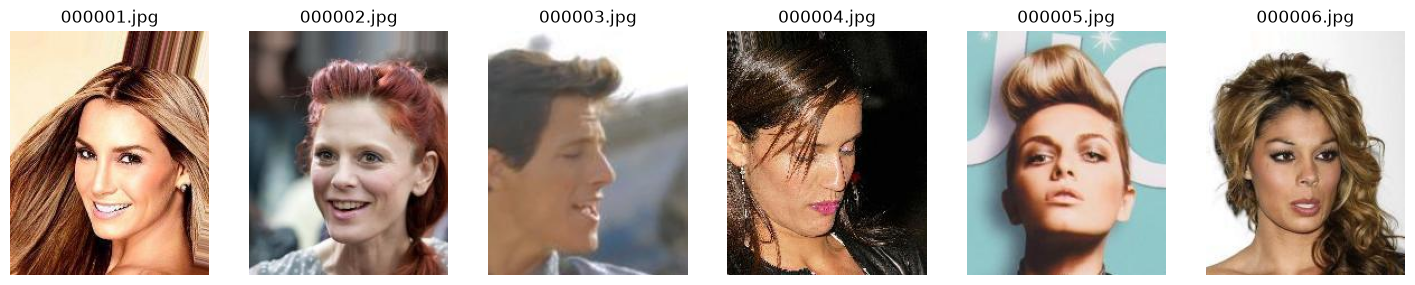

In [8]:
sample_images = identity_df["image_id"].iloc[:6].tolist()

fig, axes = plt.subplots(1, 6, figsize=(18, 4)) #This line creates a figure with 1 row and 6 columns of plots.

for i, img_name in enumerate(sample_images):      #enumerate gives you index+value (i + img_name)
    img = Image.open(os.path.join(img_dir, img_name))
    axes[i].imshow(img)
    axes[i].set_title(img_name)
    axes[i].axis("off") #will not give name for the axes 
plt.show()

### preprocessing pipeline - face detection + cropping (MTCNN)
MTCNN handles detection, cropping, and resizing in one step, and gives landmarks for alignment.

detection probability: 1.0
cropped face shape: torch.Size([3, 160, 160])


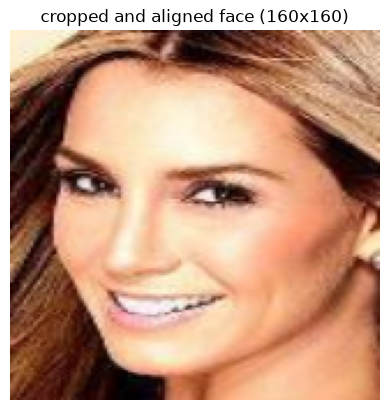

In [9]:
from facenet_pytorch import MTCNN

mtcnn = MTCNN(image_size=160, margin=20, post_process=False, device=device)

# test on one image
# .convert("RGB") because a few CelebA files are not 3-channel, and a grayscale one
# would come out as [1,160,160] and break everything downstream
test_img = Image.open(os.path.join(img_dir, sample_images[0])).convert("RGB")
face, prob = mtcnn(test_img, return_prob=True)
print("detection probability:", round(prob,2))
print("cropped face shape:", face.shape if face is not None else None) #[3,160,160] --> 3 channels (RGB color), (160,160): (height,width)

plt.imshow(face.permute(1, 2, 0).int().numpy()) # int() to convert the pixle value to integer   Why .numpy()? convert the PyTorch tensor into a NumPy array before displaying it.
#why using permute? because PyTorch stores images as:(Channel, Height, Width), But Matplotlib expects:(Height, Width, Channel)
#face.permute(1,2,0) reorders the dimensions:

plt.title("cropped and aligned face (160x160)")
plt.axis("off")
plt.show()

### get landmarks for one image (used for alignment)

In [10]:
boxes, probs, landmarks = mtcnn.detect(test_img, landmarks=True)
print("box:", boxes)
print("landmarks (left eye, right eye, nose, mouth left, mouth right):")
print(landmarks)
# each feature output is pair (x,y)
# x = horizontal position (distance from the left edge of the image)
# y = vertical position (distance from the top edge of the image)

box: [[52.763511657714844 59.07532501220703 148.5936737060547
  187.2781982421875]]
landmarks (left eye, right eye, nose, mouth left, mouth right):
[[[67.9554443359375 108.71745300292969]
  [109.90554809570312 111.73422241210938]
  [79.2925796508789 141.52108764648438]
  [70.02278137207031 154.99472045898438]
  [108.78797912597656 157.0271453857422]]]


### manual alignment example
MTCNN aligns internally, but here is the underlying idea (rotate so eyes are level) - useful to explain in the defense.

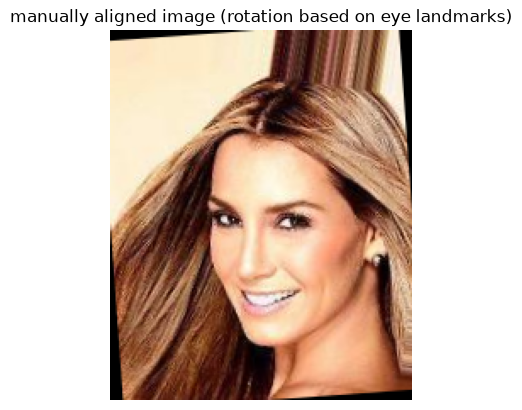

In [11]:
import cv2

left_eye = landmarks[0][0] #get the left eye 
right_eye = landmarks[0][1] #get the right eye

#Calculate the vertical difference
dy = right_eye[1] - left_eye[1]

#Calculate the horizontal distance
dx = right_eye[0] - left_eye[0]

#Calculate the rotation angle
angle = np.degrees(np.arctan2(dy, dx))

#Convert image format
img_cv = cv2.cvtColor(np.array(test_img), cv2.COLOR_RGB2BGR)

#Get image dimensions
h, w = img_cv.shape[:2]

#Find the center between the eyes
eyes_center = ((left_eye[0] + right_eye[0]) / 2, (left_eye[1] + right_eye[1]) / 2)

#Create rotation matrix
rot_matrix = cv2.getRotationMatrix2D(eyes_center, angle, 1.0)  # 1 --> keep the same size

#Apply rotation
aligned_img = cv2.warpAffine(img_cv, rot_matrix, (w, h))

#Display the aligned image + conver back from BGR to RGB because Matplotlib expects RGB.
plt.imshow(cv2.cvtColor(aligned_img, cv2.COLOR_BGR2RGB))
plt.title("manually aligned image (rotation based on eye landmarks)")
plt.axis("off")
plt.show()

### run preprocessing on a batch and save (detect + crop + align + resize)

In [12]:
# NOTE: this is test only (200 images, saved as .jpg).
# .jpg is lossy, and lossy compression eats the exact pixel values that FGSM/PGD
# perturbations live in - so this folder is throwaway. the real preprocessing is
# the v2 section below (png, no face detection dropped silently, manifest file).
output_dir = "./celeba/preprocessed"
os.makedirs(output_dir, exist_ok=True)

n_images = 200  # small batch for week 1 testing, scale up later
processed = 0
skipped = 0

for img_name in identity_df["image_id"].iloc[:n_images]:
    img_path = os.path.join(img_dir, img_name)
    img = Image.open(img_path).convert("RGB")

    face = mtcnn(img)

    if face is None:
        skipped += 1
        continue

    # face is CxHxW tensor, values 0-255 since post_process=False
    face_np = face.permute(1, 2, 0).byte().numpy()

    save_path = os.path.join(output_dir, img_name)
    Image.fromarray(face_np).save(save_path)
    processed += 1

print("processed:", processed)
print("skipped (no face detected):", skipped)

processed: 199
skipped (no face detected): 1


## normalization
normalization happens at model-input time, not when saving preprocessed images (keeps saved images viewable).

### **Pipeline 1**: Normalize(mean=0.5,std=0.5) Used for:
CNNs you train,
GANs you train,
Blue Agent classifier

### **Pipeline 2**: fixed_image_standardization used for :
Pretrained FaceNet,
ArcFace (with its own expected preprocessing),
Recognition model

In [13]:
from torchvision import transforms

preprocess = transforms.Compose([ # compose -> Apply these transformations one after another
    transforms.ToTensor(), # convert the pixles value from (0 to 255) to (0 to 1)
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) # convert from (0 to 1) to (-1 to 1) because Many CNNs and GANs are trained on this range.
])

sample_face_name = os.listdir(output_dir)[0]
sample_face = Image.open(os.path.join(output_dir, sample_face_name))
normalized_tensor = preprocess(sample_face)

print("normalized tensor shape:", normalized_tensor.shape)
print("min value:", round(normalized_tensor.min().item(), 3))
print("max value:", round(normalized_tensor.max().item(), 3))

# the 0.5/0.5 version above gives [-1, 1], which is what a GAN / a CNN we train
# ourselves wants. but pretrained facenet was trained with (x - 127.5) / 128,
# not (x - 127.5) / 127.5. the difference is tiny (~0.4%) but it is free to get right,
# so use this transform whenever we feed the *pretrained* recognition model.
from facenet_pytorch import fixed_image_standardization # this normlization for facenet not for cnn (FaceNet was originally trained using a specific normalization formula.)

facenet_transform = transforms.Compose([
    np.float32,                    # PIL -> float array 0..255 (ToTensor would rescale a uint8 image to 0..1)
    transforms.ToTensor(),
    fixed_image_standardization,   # (x - 127.5) / 128
])

facenet_tensor = facenet_transform(sample_face)
print("facenet tensor range:", round(facenet_tensor.min().item(), 3), "->", round(facenet_tensor.max().item(), 3))

normalized tensor shape: torch.Size([3, 160, 160])
min value: -1.0
max value: 1.0
facenet tensor range: -0.996 -> 0.996


### Preprocessing v2 - filtering, illumination normalization, split, augmentation
what changed vs v1:
- process the **whole working set**, not 500 images, in GPU mini-batches (batching is a speed trick, not a limit on the data)
- write a **manifest csv** of what actually got preprocessed, and split from that (v1 split from a list of images that were never preprocessed)
- resumable: stop the cell and re-run it, it picks up where it stopped
- save as **png** (lossless) - jpg would destroy the exact pixels FGSM/PGD perturbations live in

### identity filtering (drop identities with too few images)

In [22]:
# rebuild identity counts, keep only identities with enough images to learn from
# this is a PRE-filter (before preprocessing). some of these images will still be
# dropped by MTCNN (no face / low confidence), so we re-check the counts afterwards.
identity_counts = identity_df["identity"].value_counts()
valid_identities = identity_counts[identity_counts >= 5].index

print("identities before filtering:", identity_df["identity"].nunique())
print("identities after filtering (>=5 images):", len(valid_identities))

filtered_df = identity_df[identity_df["identity"].isin(valid_identities)].reset_index(drop=True)
print("images before filtering:", len(identity_df))
print("images after identity filtering:", len(filtered_df))

identities before filtering: 10177
identities after filtering (>=5 images): 9343
images before filtering: 202599
images after identity filtering: 200288


### build the working set (cap images per identity)
this is the answer to "full dataset or batch?" - neither. we preprocess a **stratified subset**: every identity is kept, but capped at N images each.
we do NOT need all 200k images, and here is why:
  - facenet is pretrained -> we only need images to *evaluate* verification, not to train it
  - the DCGAN (red agent) trains fine on ~40k faces
  - the blue agent is a 4-class CNN (genuine / gan / fgsm / pgd) -> ~10k per class is plenty
 capping at 5 images per identity keeps ALL 9343 identities (good for verification,
 where identity coverage matters more than images per identity) and gives us ~47k faces.

 set max_per_identity = None to preprocess the full filtered set (~200k images, ~8 GB of png).

In [23]:
max_per_identity = 5

if max_per_identity is None:
    subset_df = filtered_df.copy()
else:
    subset_df = (
        filtered_df
        .groupby("identity", group_keys=False) # Don't add the group name (identity) to the index.
        .head(max_per_identity)          # takes the first 5 rows of each identity
        .reset_index(drop=True)
    )

print("identities in working set:", subset_df["identity"].nunique())
print("images to preprocess:", len(subset_df))
print("estimated disk (png 160x160, ~40 KB each):", round(len(subset_df) * 40 / 1024 / 1024, 2), "GB")

identities in working set: 9343
images to preprocess: 46715
estimated disk (png 160x160, ~40 KB each): 1.78 GB


### detection confidence filtering + CLAHE illumination normalization + save as PNG
runs over the **whole working set** in GPU mini-batches, drops low-confidence detections, applies CLAHE on the luminance channel, and records every kept image in a manifest.

the manifest is the important part: it is the single source of truth for what is actually on disk, and it already has a `label` column so the Red Agent can append its `gan` / `fgsm` / `pgd` rows to the same file later.

In [24]:
import cv2

output_dir = "./celeba/preprocessed_v2"
os.makedirs(output_dir, exist_ok=True)

manifest_path = os.path.join(project_dir, "manifest_v2.csv") # project_dir -> the main folder path 
skipped_path = os.path.join(project_dir, "skipped_v2.csv")   # images MTCNN could not use, kept so we do not retry them every run

min_confidence = 0.90 # Only accept detections whose confidence is at least 90%.
batch_size = 32 # This speeds up GPU processing.                  
resume = True #If preprocessing stopped yesterday, today it continues from where it stopped instead of starting over.

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def prob_to_float(p):
    '''
    MTCNN returns the detection probability in 3 different shapes depending on how it
    was called: a plain float (single image), a 1 element array (batch), or [None]
    (batch, no face found). this normalizes all of them to float or None.
    '''
    if p is None:
        return None
    p = np.atleast_1d(p).ravel()
    if len(p) == 0 or p[0] is None:
        return None
    return float(p[0])


def detect_faces_batch(pil_images):
    '''
    runs MTCNN on a list of images at once - on GPU this is several times faster than
    calling it one image at a time.

    two things to know:
    1) batching requires all images to be the same size. CelebA aligned images are all
       178x218, so we are fine. (raw/unaligned images would need to be resized first.)
    2) facenet-pytorch has a bug: if SOME images in the batch have no detectable face,
       the batched call raises instead of returning None for them. so we catch it and
       redo that one batch image-by-image. rare (~1 in 200 CelebA images), so it costs
       almost nothing.
    '''
    try:
        faces, probs = mtcnn(pil_images, return_prob=True)
        return faces, [prob_to_float(p) for p in probs]
    except (ValueError, RuntimeError): # if the batch crash , it will automatically process them one by one
        faces, probs = [], []
        for img in pil_images:
            face, prob = mtcnn(img, return_prob=True)
            faces.append(face)
            probs.append(prob_to_float(prob))
        return faces, probs


# resume support: anything already preprocessed (in the manifest) or already rejected
# (in the skipped file) is done - do not touch it again
if resume and os.path.exists(manifest_path):
    done_df = pd.read_csv(manifest_path)
    print("resuming - already preprocessed:", len(done_df))
else:
    done_df = pd.DataFrame()

if resume and os.path.exists(skipped_path):
    old_skipped_df = pd.read_csv(skipped_path)
    print("resuming - already rejected:", len(old_skipped_df))
else:
    old_skipped_df = pd.DataFrame()

done_ids = set(done_df["image_id"]) if len(done_df) else set() # If done_df is not empty, done_ids becomes a set of all processed image IDs.
done_ids |= set(old_skipped_df["image_id"]) if len(old_skipped_df) else set() # |=  --> union 

todo_names = [n for n in subset_df["image_id"] if n not in done_ids]
identity_of = dict(zip(subset_df["image_id"], subset_df["identity"]))
print("images to process now:", len(todo_names))

manifest_rows = []
skipped_rows = []
processed = 0
skipped_low_conf = 0
skipped_no_face = 0
start_time = time.time()

for start in range(0, len(todo_names), batch_size): #loop through batches 
    chunk = todo_names[start:start + batch_size] #Takes a slice of image names for the current batch.
    pil_batch = [Image.open(os.path.join(img_dir, n)).convert("RGB") for n in chunk]    

    faces, probs = detect_faces_batch(pil_batch) # Runs MTCNN on the whole batch.

    for img_name, face, prob in zip(chunk, faces, probs):
        if face is None or prob is None:
            skipped_no_face += 1
            skipped_rows.append({"image_id": img_name, "reason": "no_face"})
            continue

        if prob < min_confidence:
            skipped_low_conf += 1
            skipped_rows.append({"image_id": img_name, "reason": "low_confidence", "det_prob": round(prob, 4)})
            continue

        face_np = face.permute(1, 2, 0).byte().cpu().numpy()

        # CLAHE on luminance channel only (LAB color space), keeps color info intact
        face_lab = cv2.cvtColor(face_np, cv2.COLOR_RGB2LAB) # Convert RGB to LAB color space.
        l_channel, a_channel, b_channel = cv2.split(face_lab) # Separate brightness (L) from color (A, B).
        l_channel_eq = clahe.apply(l_channel) # Improve contrast only on brightness.
        face_lab_eq = cv2.merge((l_channel_eq, a_channel, b_channel)) 
        face_eq = cv2.cvtColor(face_lab_eq, cv2.COLOR_LAB2RGB)

        save_name = img_name.replace(".jpg", ".png")
        save_path = os.path.join(output_dir, save_name)
        Image.fromarray(face_eq).save(save_path)
        processed += 1

        manifest_rows.append({
            "image_id": img_name,                     # original celeba filename
            "file_name": save_name,                   # what we actually saved (png)
            "identity": identity_of[img_name],
            "det_prob": round(prob, 4),               # mtcnn confidence, useful later for the input-quality score
            "label": "genuine",                       # red agent will append gan / fgsm / pgd rows here
            "source": "celeba",
        })

    # progress every ~50 batches so we can see it is alive and estimate the total time
    if (start // batch_size) % 50 == 0 and start > 0:
        elapsed = time.time() - start_time
        rate = (start + len(chunk)) / elapsed
        remaining = (len(todo_names) - start - len(chunk)) / max(rate, 1e-6)
        print(f"  {start + len(chunk)}/{len(todo_names)}  |  {rate:.1f} img/s  |  ~{remaining/60:.1f} min left")

# write the manifest (old rows + new rows)
new_df = pd.DataFrame(manifest_rows)
manifest_df = pd.concat([done_df, new_df], ignore_index=True) if len(done_df) else new_df
manifest_df.to_csv(manifest_path, index=False)

# write the rejected images too - this is also a number for the report
# ("x images dropped: no face detected / detection confidence below 0.90")
new_skipped_df = pd.DataFrame(skipped_rows)
skipped_df = pd.concat([old_skipped_df, new_skipped_df], ignore_index=True) if len(old_skipped_df) else new_skipped_df
if len(skipped_df):
    skipped_df.to_csv(skipped_path, index=False)

print()
print("processed this run:", processed)
print("skipped (low detection confidence):", skipped_low_conf)
print("skipped (no face detected):", skipped_no_face)
print("total in manifest:", len(manifest_df))
print("total rejected:", len(skipped_df))
print("elapsed:", round((time.time() - start_time) / 60, 1), "min")
print("manifest saved to:", manifest_path)

images to process now: 46715
  1632/46715  |  21.0 img/s  |  ~35.8 min left
  3232/46715  |  20.0 img/s  |  ~36.2 min left
  4832/46715  |  14.1 img/s  |  ~49.4 min left
  6432/46715  |  15.3 img/s  |  ~43.8 min left
  8032/46715  |  16.0 img/s  |  ~40.3 min left
  9632/46715  |  16.6 img/s  |  ~37.3 min left
  11232/46715  |  17.3 img/s  |  ~34.2 min left
  12832/46715  |  17.2 img/s  |  ~32.9 min left
  14432/46715  |  17.5 img/s  |  ~30.8 min left
  16032/46715  |  17.8 img/s  |  ~28.7 min left
  17632/46715  |  16.9 img/s  |  ~28.7 min left
  19232/46715  |  17.1 img/s  |  ~26.9 min left
  20832/46715  |  17.3 img/s  |  ~24.9 min left
  22432/46715  |  13.0 img/s  |  ~31.2 min left
  24032/46715  |  13.3 img/s  |  ~28.4 min left
  25632/46715  |  13.6 img/s  |  ~25.8 min left
  27232/46715  |  13.8 img/s  |  ~23.5 min left
  28832/46715  |  13.7 img/s  |  ~21.8 min left
  30432/46715  |  13.9 img/s  |  ~19.6 min left
  32032/46715  |  14.1 img/s  |  ~17.3 min left
  33632/46715  | 

### compare before/after CLAHE (visual check)
three panels, because "original vs preprocessed" mixes two changes (the crop AND the CLAHE). the middle panel isolates what CLAHE actually did.

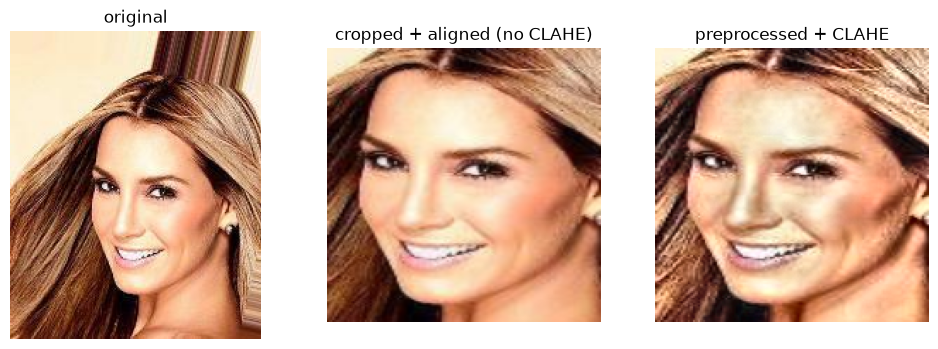

In [25]:
sample_name = sorted(os.listdir(output_dir))[0]   # sorted() - os.listdir order is not guaranteed
original_name = sample_name.replace(".png", ".jpg")

# 1) the original full image, before anything
before_img = Image.open(os.path.join(img_dir, original_name)).convert("RGB")

# 2) same face, cropped + aligned by MTCNN but WITHOUT clahe
face_raw = mtcnn(before_img)
face_no_clahe = Image.fromarray(face_raw.permute(1, 2, 0).byte().cpu().numpy())

# 3) the final preprocessed version (crop + align + clahe)
after_img = Image.open(os.path.join(output_dir, sample_name))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(before_img)
axes[0].set_title("original")
axes[0].axis("off")
axes[1].imshow(face_no_clahe)
axes[1].set_title("cropped + aligned (no CLAHE)")
axes[1].axis("off")
axes[2].imshow(after_img)
axes[2].set_title("preprocessed + CLAHE")
axes[2].axis("off")
plt.show()

### identity-level train / val / test split
splitting by identity (not by image) so the same person never appears in both train and test.

this is the right split for **verification** (open set: "are these two faces the same person?"), which is what VigilantFace does - the model must work on people it has never seen. if we ever fine-tune a classifier *over identities* instead, this split would have to change, and that is a good thing to be able to say in the defense.

In [26]:
from sklearn.model_selection import train_test_split

# IMPORTANT: we split from the MANIFEST, not from filtered_df.
# filtered_df is the list of images we *wanted*. the manifest is the list of images that
# actually exist on disk after MTCNN dropped the undetectable / low-confidence ones.
# splitting from filtered_df would write filenames into the split csvs that never got
# preprocessed - and the Dataset class in week 2 would then crash on missing files.
manifest_df = pd.read_csv(manifest_path)

# preprocessing dropped a few images per identity, so re-check the counts here.
# min 2 is the hard floor (you need 2 images of a person to build one positive
# verification pair); 3 gives a little margin.
min_images_after = 3

post_counts = manifest_df["identity"].value_counts()
keep_ids = post_counts[post_counts >= min_images_after].index
split_df = manifest_df[manifest_df["identity"].isin(keep_ids)].reset_index(drop=True)

print("identities in manifest:", manifest_df["identity"].nunique())
print(f"identities kept (>={min_images_after} preprocessed images):", len(keep_ids))
print("images kept:", len(split_df), "of", len(manifest_df))
print()

unique_ids = split_df["identity"].unique()

train_ids, temp_ids = train_test_split(unique_ids, test_size=0.3, random_state=42)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5, random_state=42)

print("train identities:", len(train_ids))
print("val identities:", len(val_ids))
print("test identities:", len(test_ids))

train_df = split_df[split_df["identity"].isin(train_ids)].reset_index(drop=True)
val_df = split_df[split_df["identity"].isin(val_ids)].reset_index(drop=True)
test_df = split_df[split_df["identity"].isin(test_ids)].reset_index(drop=True)

print("train images:", len(train_df))
print("val images:", len(val_df))
print("test images:", len(test_df))

train_df.to_csv(os.path.join(project_dir, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(project_dir, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(project_dir, "test_split.csv"), index=False)
print("splits saved to", project_dir)

identities in manifest: 9343
identities kept (>=3 preprocessed images): 9342
images kept: 46580 of 46581

train identities: 6539
val identities: 1401
test identities: 1402
train images: 32597
val images: 6986
test images: 6997
splits saved to ./celeba


### sanity checks (run before starting week 2)
if any of these fail, week 2 will fail in a way that is much harder to debug.

In [27]:
# 1) every file listed in the splits really exists on disk
missing = 0
for df_name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    miss = [f for f in df["file_name"] if not os.path.exists(os.path.join(output_dir, f))]
    missing += len(miss)
    print(f"{df_name}: {len(df)} rows, {len(miss)} missing files")

# 2) no identity leaks across splits (this would silently inflate our accuracy)
overlap_tr_va = set(train_df["identity"]) & set(val_df["identity"])
overlap_tr_te = set(train_df["identity"]) & set(test_df["identity"])
overlap_va_te = set(val_df["identity"]) & set(test_df["identity"])
print("identity overlap train/val:", len(overlap_tr_va))
print("identity overlap train/test:", len(overlap_tr_te))
print("identity overlap val/test:", len(overlap_va_te))

# 3) images per identity - we need >=2 in val/test to build positive verification pairs
print("min images per identity (val):", val_df["identity"].value_counts().min())
print("min images per identity (test):", test_df["identity"].value_counts().min())

# 4) all saved images are the shape we think they are
sample_check = Image.open(os.path.join(output_dir, train_df["file_name"].iloc[0]))
print("sample image:", sample_check.size, sample_check.mode)

assert missing == 0, "some split files are missing from disk"
assert len(overlap_tr_va) == len(overlap_tr_te) == len(overlap_va_te) == 0, "identity leakage between splits"
print()
print("all checks passed - dataset is ready for week 2")

train: 32597 rows, 0 missing files
val: 6986 rows, 0 missing files
test: 6997 rows, 0 missing files
identity overlap train/val: 0
identity overlap train/test: 0
identity overlap val/test: 0
min images per identity (val): 4
min images per identity (test): 3
sample image: (160, 160) RGB

all checks passed - dataset is ready for week 2


### step 5: data augmentation (train set only - never apply to val/test)

In [28]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10, fill=0),       # fill=0 so the corners are black, not undefined
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomResizedCrop(size=160, scale=(0.9, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# WARNING for later (weeks 5-6): this augmentation is for GENUINE images only.
# never run ColorJitter / RandomResizedCrop / rotation on FGSM or PGD samples -
# those transforms are literally input-transformation *defenses*, they smear out the
# adversarial perturbation. if we augment the adversarial class, the blue agent will
# be trained on attacks we already half-destroyed and its accuracy will be a lie.
# for the blue agent: keep flips at most, or no augmentation at all.

# quick test on one preprocessed image
sample_img = Image.open(os.path.join(output_dir, sample_name))
augmented = train_transform(sample_img)
print("augmented tensor shape:", augmented.shape)

augmented tensor shape: torch.Size([3, 160, 160])


### visualize augmentation (same image, different random augmentations each time)

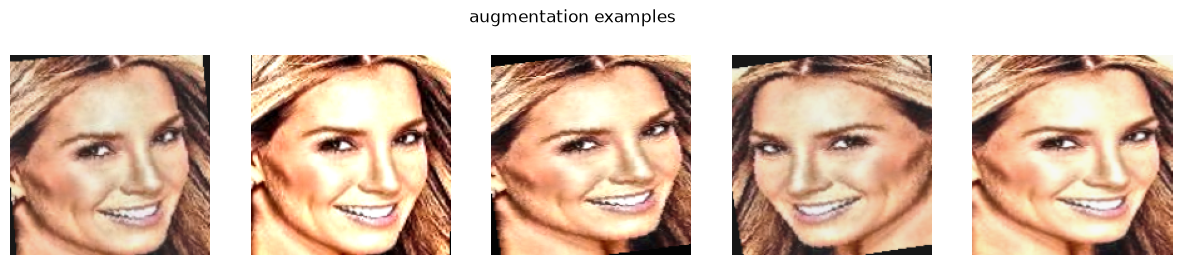

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    aug_img = train_transform(sample_img)
    aug_img_display = (aug_img * 0.5 + 0.5).clip(0, 1)  # unnormalize for display, clip so matplotlib does not complain
    axes[i].imshow(aug_img_display.permute(1, 2, 0).numpy())
    axes[i].axis("off")
plt.suptitle("augmentation examples")
plt.show()

### handoff to week 2

what this notebook produces:

| file | what it is |
|---|---|
| `./celeba/preprocessed_v2/*.png` | cropped + aligned + CLAHE faces, 160x160, lossless |
| `./celeba/manifest_v2.csv` | the source of truth: `image_id, file_name, identity, det_prob, label, source` |
| `./celeba/train_split.csv` / `val_split.csv` / `test_split.csv` | identity-disjoint splits, built from the manifest |

**one thing to get right before week 5 (attacks):** the Red Agent must generate FGSM/PGD samples *from these preprocessed images*, i.e. after the crop and after CLAHE - not from raw CelebA jpgs. if genuine images go through CLAHE and adversarial ones do not, the Blue Agent will learn to detect *CLAHE*, not adversarial noise, and it will score ~99% while being completely useless. same preprocessing lineage for all 4 classes.